# Basic Analysis

## Setup

### Load

In [ ]:
import numpy as np
import pandas as pd

import seaborn as sns
import matplotlib.pyplot as plt
import pingouin as pg

from scipy.stats import pearsonr, linregress, ttest_rel
from mpl_toolkits.axes_grid1 import make_axes_locatable

### Data

In [100]:
df = pd.read_csv("data/data_integrated_irl.csv", encoding="utf-8-sig")
df_desktop = df[df["web"] == False]
df_web = df[df["web"] == True]

print(f"N={len(df_desktop)}+{len(df_web)}={len(df)}")
df

N=53+229=282


,subj_id,age,gender,BIS,BIS_motor,BIS_nonplanning,BIS_attentional,BIS_same_response,STAI,STAI_S,...,sideway_movements_toward_visible_crosswalk_danger_zone_cnt_high_penalty_session2,DDT_mean_log_k,CRA_mean_alpha,web,safest_road_crossing_irl,waiting_for_car_to_pass_irl,high_risk_but_empty_last_road_irl,approaching_crosswalk_in_current_road_irl,approaching_next_crosswalks_irl,move_up_toward_car_irl
0,904,22,1,73,23,31,19,-1,87,44,...,14,-3.272599,0.347513,False,0.748267,-0.258253,-0.128665,0.608656,0.356492,0.579928
1,1000,32,2,61,18,22,21,-1,84,38,...,7,-6.330838,0.660547,False,0.492620,-0.838224,-0.060370,0.450264,0.492121,0.753004
2,1001,25,2,73,20,31,22,-1,77,38,...,6,-7.961866,0.612792,False,0.663715,0.122388,-1.073019,0.427394,0.443287,0.089030
3,1002,21,2,63,22,22,19,-1,73,38,...,4,-1.564452,1.412119,False,0.223814,-0.900335,0.055749,0.549780,0.407102,0.497768
4,1003,26,2,69,22,24,23,-1,86,40,...,17,-5.378190,0.668441,False,0.464243,-0.561648,0.423064,0.572266,0.436846,0.555052
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
277,67612c302f90b2399522a2ba,56,2,57,20,22,15,-1,76,23,...,0,NaN,NaN,True,0.389329,-0.888709,-0.620859,0.277520,0.617685,0.589324
278,69932ccc26c39ba9a7a39642,66,2,46,16,17,13,-1,49,21,...,0,NaN,NaN,True,0.125390,0.445344,-0.175946,0.520319,0.280906,0.254887
279,69c8053e8f584e930c1722b1,33,1,71,23,23,25,-1,64,28,...,2,NaN,NaN,True,0.677933,-0.138321,-0.190641,0.363318,0.409584,0.261878
280,6942a793a0943732e26bc8a2,59,1,74,30,29,15,-1,76,34,...,0,NaN,NaN,True,-0.227059,-0.546543,-0.001737,0.772755,0.625462,0.342434


### Util

In [101]:
def print_summary(data, name):
    print(f"{name}: mean = {data.mean():.2f}, std = {data.std():.2f} (min={data.min()} ~ max={data.max()})")

In [102]:
def scatter_plot_with_line_regression(plot, x, y, xlabel, ylabel, title, pval_verbose=False, ylim = None, web=None, force_title=False):
    if web is None:
        dataframe = df
        if not force_title:
            title = f"{title} (combined)"
    elif web:
        dataframe = df[df["web"] == True]
        if not force_title:
            title = f"{title} (web)"
    else:
        dataframe = df[df["web"] == False]
        if not force_title:
            title = f"{title} (desktop)"
    subj_ids = list(dataframe["subj_id"])
    mask = df["subj_id"].isin(subj_ids) & x.notna() & y.notna()
    x = x[mask]
    y = y[mask]
    plot.scatter(x, y)
    slope, intercept, r_value, p_value, std_err = linregress(x, y)
    line_x = np.linspace(x.min(), x.max(), 100)
    line_y = slope * line_x + intercept
    plot.plot(line_x, line_y, color="red")

    plot.set_xlabel(xlabel, fontsize=14)
    plot.set_ylabel(ylabel, fontsize=14)
    plot.tick_params(axis='both', labelsize=12)
    if ylim is not None:
        plot.set_ylim(ylim[0], ylim[1])

    significance = ""
    if p_value < 0.001:
        significance = "***"
    elif p_value < 0.01:
        significance = "**"
    elif p_value < 0.05:
        significance = "*"
    if pval_verbose:
        plot.set_title(f"{title}\nr={r_value:.3f}, p={p_value:.4f}{significance}", fontsize=16)
    else:
        plot.set_title(f"{title}\nr={r_value:.3f}, p={p_value:.3f}{significance}", fontsize=16)

In [103]:
def significance_star(p):
    if np.isnan(p):
        return ""
    if p < 0.001:
        return "***"
    elif p < 0.01:
        return "**"
    elif p < 0.05:
        return "*"
    return ""


### Features and Questionairres list

In [104]:
behavior_cols = [
    "average_score_full",
    "bonus_score_episode_ratio",
    "road_crossing_success_ratio_total",
    "sideway_movements_in_crosswalk_not_visible_safe_zone_cnt_high_to_low_penalty",

    "run_over_episode_ratio",
]

behavior_col_names = [
    "Average Score",
    "Episode\nClear Ratio",
    "Road Crossing\nSuccess Ratio",
    "Crosswalk\nSearching",

    "Run Over Ratio",
]

irl_cols = [
    "safest_road_crossing_irl",
    "waiting_for_car_to_pass_irl",

    "high_risk_but_empty_last_road_irl",
    "approaching_crosswalk_in_current_road_irl",
    "approaching_next_crosswalks_irl",
    "move_up_toward_car_irl",
]

irl_col_names = [
    "[IRL] Safest\nRoad Crossing",
    "[IRL] Waiting in\nCrosswalk for\nCar to Pass",

    "[IRL] High Risk but\nEmpty Last Road",
    "[IRL] Approaching\nCrosswalk in\nCurrent Road",
    "[IRL] Approaching\nNext Crosswalks",
    "[IRL] Move Up\nToward Car",
]

all_feature_cols = behavior_cols + irl_cols
all_feature_col_names = behavior_col_names + irl_col_names

all_target_cols = [
  "DOSPERT",
  "DOSPERT_ETH",
  "DOSPERT_FIN",
  "DOSPERT_HEA",
  "DOSPERT_REC",
  "DOSPERT_SOC",
  
  "BIS",
  "BIS_motor",
  "BIS_nonplanning",
  "BIS_attentional",
  
  "STAI",
  "STAI_S",
  "STAI_T",
]

rename_dict = {
  "DOSPERT": "DOSPERT",
  "DOSPERT_ETH": "DOSPERT (Ethical)",
  "DOSPERT_FIN": "DOSPERT (Financial)",
  "DOSPERT_HEA": "DOSPERT (Health Safety)",
  "DOSPERT_REC": "DOSPERT (Recreational)",
  "DOSPERT_SOC": "DOSPERT (Social)",

  "BIS":             "BIS",
  "BIS_motor":       "BIS (Motor)",
  "BIS_nonplanning": "BIS (Non-planning)",
  "BIS_attentional": "BIS (Attentional)",

  "STAI":     "STAI",
  "STAI_S":   "STAI-S",
  "STAI_T":   "STAI-T",

  "IGDS":     "IGDS",
  "IAT":      "IAT",
  "S_UPPS_P": "S-UPPS-P",
}
for i in range(len(all_feature_cols)):
    rename_dict[all_feature_cols[i]] = all_feature_col_names[i]


## Demographics

In [105]:
print_summary(df["age"], "[Combined] Age")
print(f"{len(df[df['gender'] == 1])} females")
print(f"{len(df[df['gender'] == 2])} males")
print(f"{len(df[(df['gender'] != 1) & (df['gender'] != 2)])} others")

print()

if len(df[df['age'] < 18]) == 0:
    print("everyone is an adult")
else:
    print(f"{len(df[df['age'] < 18])} non-adults detected")

[Combined] Age: mean = 34.67, std = 10.91 (min=18 ~ max=66)
151 females
124 males
7 others

everyone is an adult


In [106]:
print_summary(df_desktop["age"], "[Desktop] Age")
print(f"{len(df_desktop[df_desktop['gender'] == 1])} females")
print(f"{len(df_desktop[df_desktop['gender'] == 2])} males")
print(f"{len(df_desktop[(df_desktop['gender'] != 1) & (df_desktop['gender'] != 2)])} others")

[Desktop] Age: mean = 24.83, std = 4.87 (min=19 ~ max=43)
30 females
23 males
0 others


In [107]:
print_summary(df_web["age"], "[Web] Age")
print(f"{len(df_web[df_web['gender'] == 1])} females")
print(f"{len(df_web[df_web['gender'] == 2])} males")
print(f"{len(df_web[(df_web['gender'] != 1) & (df_web['gender'] != 2)])} others")

[Web] Age: mean = 36.94, std = 10.66 (min=18 ~ max=66)
121 females
101 males
7 others


## Traditional Behavior Tasks

N=53
Average Score, r=-0.2721434200818462, p=0.04868117329657999
Discounting Rate (log k), r=0.11907089040105502, p=0.3957667295534667
Risk Preference (α), r=0.018797936215073092, p=0.8937192544045386


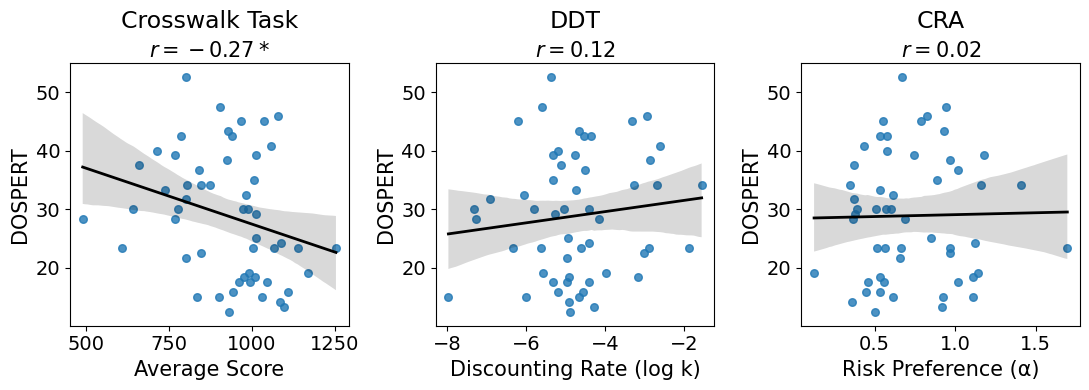

In [108]:
def plot_regression(
    ax,
    data,
    x,
    y="DOSPERT",
    title=None,
    xlabel=None,
    ylabel=None,
    fontsize=16
):
    # Remove missing values
    tmp = data[[x, y]].dropna()

    # Pearson correlation
    r, p = pearsonr(tmp[x], tmp[y])
    print(f"{xlabel}, r={r}, p={p}")
    if p < 0.001:
        sig = "***"
    elif p < 0.01:
        sig = "**"
    elif p < 0.05:
        sig = "*"
    else:
        sig = ""
    
    # Scatter + regression line + 95% CI
    sns.regplot(
        data=tmp,
        x=x,
        y=y,
        ax=ax,
        ci=95,
        scatter_kws={
            "alpha": 0.8,
            "s": 30,
            "color": "tab:blue"
        },
        line_kws={
            "linewidth": 2,
            "color": "black"
        }
    )

    # Labels
    ax.set_xlabel(xlabel if xlabel is not None else x, fontsize=fontsize-1)
    ax.set_ylabel(ylabel if ylabel is not None else y, fontsize=fontsize-1)
    ax.tick_params(axis="x", labelsize=fontsize-2)
    ax.tick_params(axis="y", labelsize=fontsize-2)
    ax.set_ylim((10.1, 55))
    # ax.set_ylim((30, 150)) # no POMP

    # Main title
    ax.set_title(title, fontsize=fontsize+1, pad=fontsize+9)
    # Correlation below title
    ax.text(
        0.5, 1.005,
        f"$r = {r:.2f}{sig}$",
        transform=ax.transAxes,
        ha="center",
        va="bottom",
        fontsize=fontsize-1
    )
    return r, p

fig, axes = plt.subplots(1, 3, figsize=(11, 4))

print(f"N={len(df_desktop)}")
plot_regression(
    axes[0],
    df_desktop,
    x="average_score_full",
    y="DOSPERT",
    # y="DOSPERT_raw", # no POMP
    title="Crosswalk Task",
    xlabel="Average Score",
    ylabel="DOSPERT"
)

plot_regression(
    axes[1],
    df_desktop,
    x="DDT_mean_log_k",
    y="DOSPERT",
    # y="DOSPERT_raw", # no POMP
    title="DDT", # Delay Discounting Task",
    xlabel="Discounting Rate (log k)",
    ylabel="DOSPERT"
)

plot_regression(
    axes[2],
    df_desktop,
    x="CRA_mean_alpha",
    y="DOSPERT",
    # y="DOSPERT_raw", # no POMP
    title="CRA",
    xlabel="Risk Preference (α)",
    ylabel="DOSPERT"
)

plt.tight_layout()

## Self-report vs Self-report

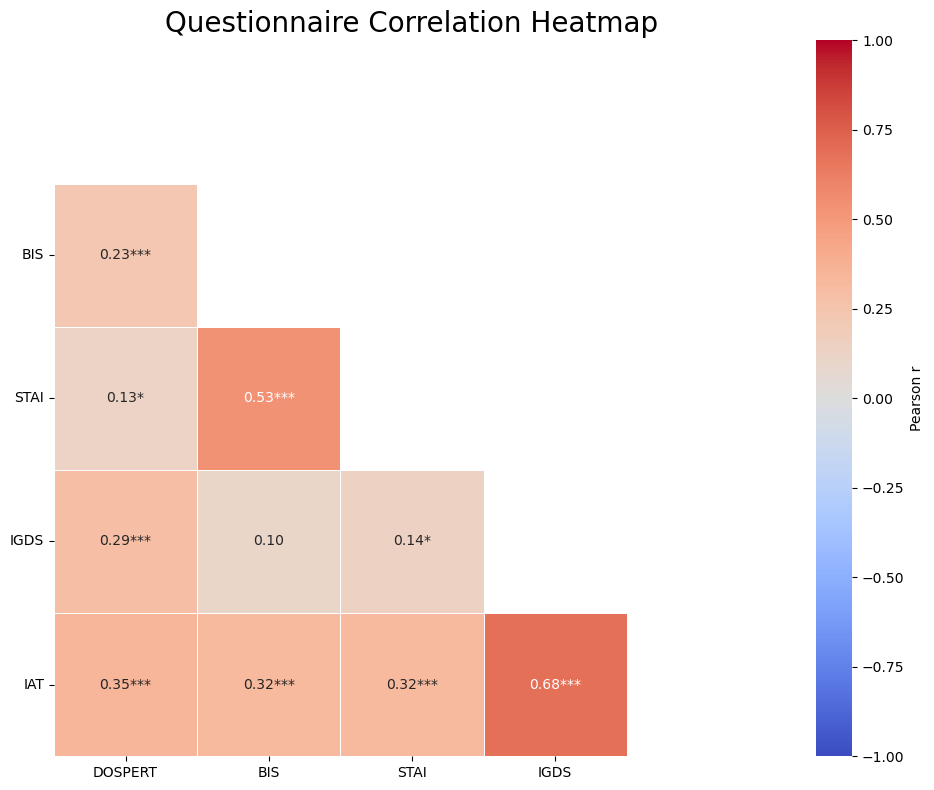

In [109]:
questionnaires = [
    "DOSPERT",
    "BIS",
    "STAI",
    "IGDS",
    "IAT",
]

def self_self(questionnaires):
    r_mat = pd.DataFrame(
        index=questionnaires,
        columns=questionnaires,
        dtype=float
    )

    p_mat = pd.DataFrame(
        index=questionnaires,
        columns=questionnaires,
        dtype=float
    )

    for q1 in questionnaires:
        for q2 in questionnaires:
            if q1 == q2: continue

            subset = df[[q1, q2]].dropna()

            r, p = pearsonr(
                subset[q1],
                subset[q2]
            )

            r_mat.loc[q1, q2] = r
            p_mat.loc[q1, q2] = p

    # Annotation with significance stars
    annot_mat = r_mat.copy().astype(str)

    for i in range(len(questionnaires)):
        for j in range(len(questionnaires)):
            r = r_mat.iloc[i, j]
            p = p_mat.iloc[i, j]

            if pd.isna(r):
                annot_mat.iloc[i, j] = ""
            else:
                stars = significance_star(p)
                annot_mat.iloc[i, j] = f"{r:.2f}{stars}"

    plot_r_mat = r_mat.iloc[1:, :-1]
    plot_annot_mat = annot_mat.iloc[1:, :-1]
    plot_mask = np.triu(np.ones_like(plot_r_mat, dtype=bool), k=1)

    # upper triangle + diagonal 제거
    mask = np.triu(np.ones_like(r_mat, dtype=bool), k=0)

    plt.figure(figsize=(10, 8))

    ax = sns.heatmap(
        r_mat,
        mask=mask,
        annot=annot_mat,
        fmt="",
        cmap="coolwarm",
        vmin=-1,
        vmax=1,
        square=True,
        linewidths=0.5,
        cbar_kws={"label": "Pearson r"}
    )
    ax.set_xticks(np.arange(len(questionnaires) - 1) + 0.5)
    ax.set_xticklabels(questionnaires[:-1], rotation=0)
    ax.set_yticks(np.arange(1, len(questionnaires)) + 0.5)
    ax.set_yticklabels(questionnaires[1:], rotation=0)

    plt.title("Questionnaire Correlation Heatmap", fontsize=20)

    plt.tight_layout()
    plt.show()

self_self(questionnaires=[
    "DOSPERT",
    "BIS",
    "STAI",
    "IGDS",
    "IAT",
])

## Risk Preference Indicators: Statistics

In [110]:
summary = df[all_feature_cols].agg(["min", "max", "mean", "std"]).T
summary = summary.rename(columns={"std": "sd"})
summary.insert(0, "feature_name", all_feature_col_names)
summary

,feature_name,min,max,mean,sd
average_score_full,Average Score,444.444444,1304.504505,877.360130,187.373509
bonus_score_episode_ratio,Episode\nClear Ratio,0.078947,0.777778,0.534638,0.121450
road_crossing_success_ratio_total,Road Crossing\nSuccess Ratio,0.869295,0.975336,0.929389,0.021863
sideway_movements_in_crosswalk_not_visible_safe_zone_cnt_high_to_low_penalty,Crosswalk\nSearching,-1.000000,1.000000,0.088764,0.264565
run_over_episode_ratio,Run Over Ratio,0.133333,0.671533,0.423769,0.096615
safest_road_crossing_irl,[IRL] Safest\nRoad Crossing,-0.599720,1.190444,0.459864,0.286763
waiting_for_car_to_pass_irl,[IRL] Waiting in\nCrosswalk for\nCar to Pass,-1.861004,0.752455,-0.310573,0.483956
high_risk_but_empty_last_road_irl,[IRL] High Risk but\nEmpty Last Road,-1.073019,1.185321,-0.205953,0.256143
approaching_crosswalk_in_current_road_irl,[IRL] Approaching\nCrosswalk in\nCurrent Road,-0.528857,1.268577,0.476132,0.229669
approaching_next_crosswalks_irl,[IRL] Approaching\nNext Crosswalks,-0.724982,0.981277,0.394068,0.220861


## Risk Preference Indicators: Correlations

In [111]:
def significance_star(p_value):
    if not np.isfinite(p_value):
        return ""
    if p_value < 0.001:
        return "***"
    if p_value < 0.01:
        return "**"
    if p_value < 0.05:
        return "*"
    return ""

def plot_measure_by_scale_heatmap(
    data,
    measure_cols=all_feature_cols,
    questionnaire_groups = [
        ("DOSPERT", 0, 5),
        ("BIS", 6, 9),
        ("STAI", 10, 12),
    ],    
    target_cols=all_target_cols,
    target_names = [
        # DOSPERT
        "DOSPERT\nTotal",
        "Ethical",
        "Financial",
        "Health/\nSafety",
        "Recreational",
        "Social",

        # BIS
        "Total",
        "Motor",
        "Non-\nplanning",
        "Attentional",

        # STAI
        "Overall",
        "State",
        "Trait",
    ],
    *,
    with_r=True,
    figsize=(17, 10),
    cell_fontsize=11,
    row_fontsize=12,
    col_fontsize=11,
    group_fontsize=14,
    show_group_names=False,
):
    # Use the previously defined names, including "[IRL]" prefixes.
    measure_names = [rename_dict.get(col, col) for col in measure_cols]
    if len(measure_cols) != len(measure_names):
        raise ValueError(
            f"Expected {len(measure_names)} measure columns, "
            f"but received {len(measure_cols)}."
        )
    if len(target_cols) != len(target_names):
        raise ValueError(
            f"Expected {len(target_names)} target columns, "
            f"but received {len(target_cols)}."
        )

    n_measures = len(measure_cols)
    n_targets = len(target_cols)

    correlation_matrix = np.full((n_measures, n_targets), np.nan, dtype=float)
    p_value_matrix = np.full( (n_measures, n_targets), np.nan, dtype=float)

    # Pearson correlations using pairwise-complete observations.
    for row_idx, measure_col in enumerate(measure_cols):
        for col_idx, target_col in enumerate(target_cols):
            subset = data[
                [measure_col, target_col]
            ].dropna()

            enough_data = len(subset) >= 3

            measure_varies = (
                subset[measure_col].nunique() > 1
                if enough_data
                else False
            )

            target_varies = (
                subset[target_col].nunique() > 1
                if enough_data
                else False
            )

            if enough_data and measure_varies and target_varies:
                r_value, p_value = pearsonr(
                    subset[measure_col],
                    subset[target_col],
                )

                correlation_matrix[row_idx, col_idx] = r_value
                p_value_matrix[row_idx, col_idx] = p_value

    fig, ax = plt.subplots(figsize=figsize)

    image = ax.imshow(
        correlation_matrix,
        vmin=-1,
        vmax=1,
        cmap="coolwarm",
        aspect="auto",
    )

    # Column labels.
    ax.set_xticks(np.arange(n_targets))
    ax.set_xticklabels(
        target_names,
        fontsize=col_fontsize,
        rotation=0,
        ha="center",
    )

    ax.xaxis.tick_top()

    ax.tick_params(
        axis="x",
        which="major",
        top=True,
        bottom=False,
        labeltop=True,
        labelbottom=False,
        pad=8,
    )

    # Row labels.
    ax.set_yticks(np.arange(n_measures))
    ax.set_yticklabels(
        measure_names,
        fontsize=row_fontsize,
    )

    # Cell borders.
    ax.set_xticks(
        np.arange(-0.5, n_targets, 1),
        minor=True,
    )

    ax.set_yticks(
        np.arange(-0.5, n_measures, 1),
        minor=True,
    )

    ax.grid(
        which="minor",
        color="white",
        linewidth=0.8,
    )

    ax.tick_params(
        which="minor",
        bottom=False,
        left=False,
    )

    # Correlation coefficients and raw-p significance stars.
    for row_idx in range(n_measures):
        for col_idx in range(n_targets):
            r_value = correlation_matrix[row_idx, col_idx]
            p_value = p_value_matrix[row_idx, col_idx]

            if not np.isfinite(r_value):
                continue

            star = significance_star(p_value)

            if with_r:
                text = f"{r_value:.2f}{star}"
            else:
                text = star

            text_color = (
                "white"
                if abs(r_value) >= 0.65
                else "black"
            )

            ax.text(
                col_idx,
                row_idx,
                text,
                ha="center",
                va="center",
                fontsize=cell_fontsize,
                color=text_color,
            )

    # Separate behavioral and IRL-derived measures.
    ax.axhline(
        4.5,
        color="black",
        linewidth=2.0,
    )

    # Separate questionnaire groups and add group headings.
    for group_idx, (group_name, start_idx, end_idx) in enumerate(questionnaire_groups):
        if start_idx < 0 or end_idx >= n_targets or start_idx > end_idx:
            raise ValueError(
                f"Invalid range for {group_name}: "
                f"({start_idx}, {end_idx}) with {n_targets} columns."
            )
        if show_group_names:
            group_center = (start_idx + end_idx) / 2

            ax.text(
                group_center,
                1.08,
                group_name,
                transform=ax.get_xaxis_transform(),
                ha="center",
                va="bottom",
                fontsize=group_fontsize,
                fontweight="bold",
                clip_on=False,
            )

            # Draw a divider after each group except the last one.
            if group_idx < len(questionnaire_groups) - 1:
                ax.axvline(
                    end_idx + 0.5,
                    color="black",
                    linewidth=2.0,
                )

    # Color bar.
    divider = make_axes_locatable(ax)
    colorbar_ax = divider.append_axes("right", size="2.5%", pad=0.25)
    colorbar = fig.colorbar(image, cax=colorbar_ax, ticks=[-1, -0.5, 0, 0.5, 1])
    colorbar.set_label("Pearson $r$", fontsize=22)
    colorbar.ax.tick_params(labelsize=20)
    fig.subplots_adjust(
        left=0.30,
        right=0.91,
        bottom=0.06,
        top=0.78 if show_group_names else 0.88,
    )

### Desktop/Web/Combined

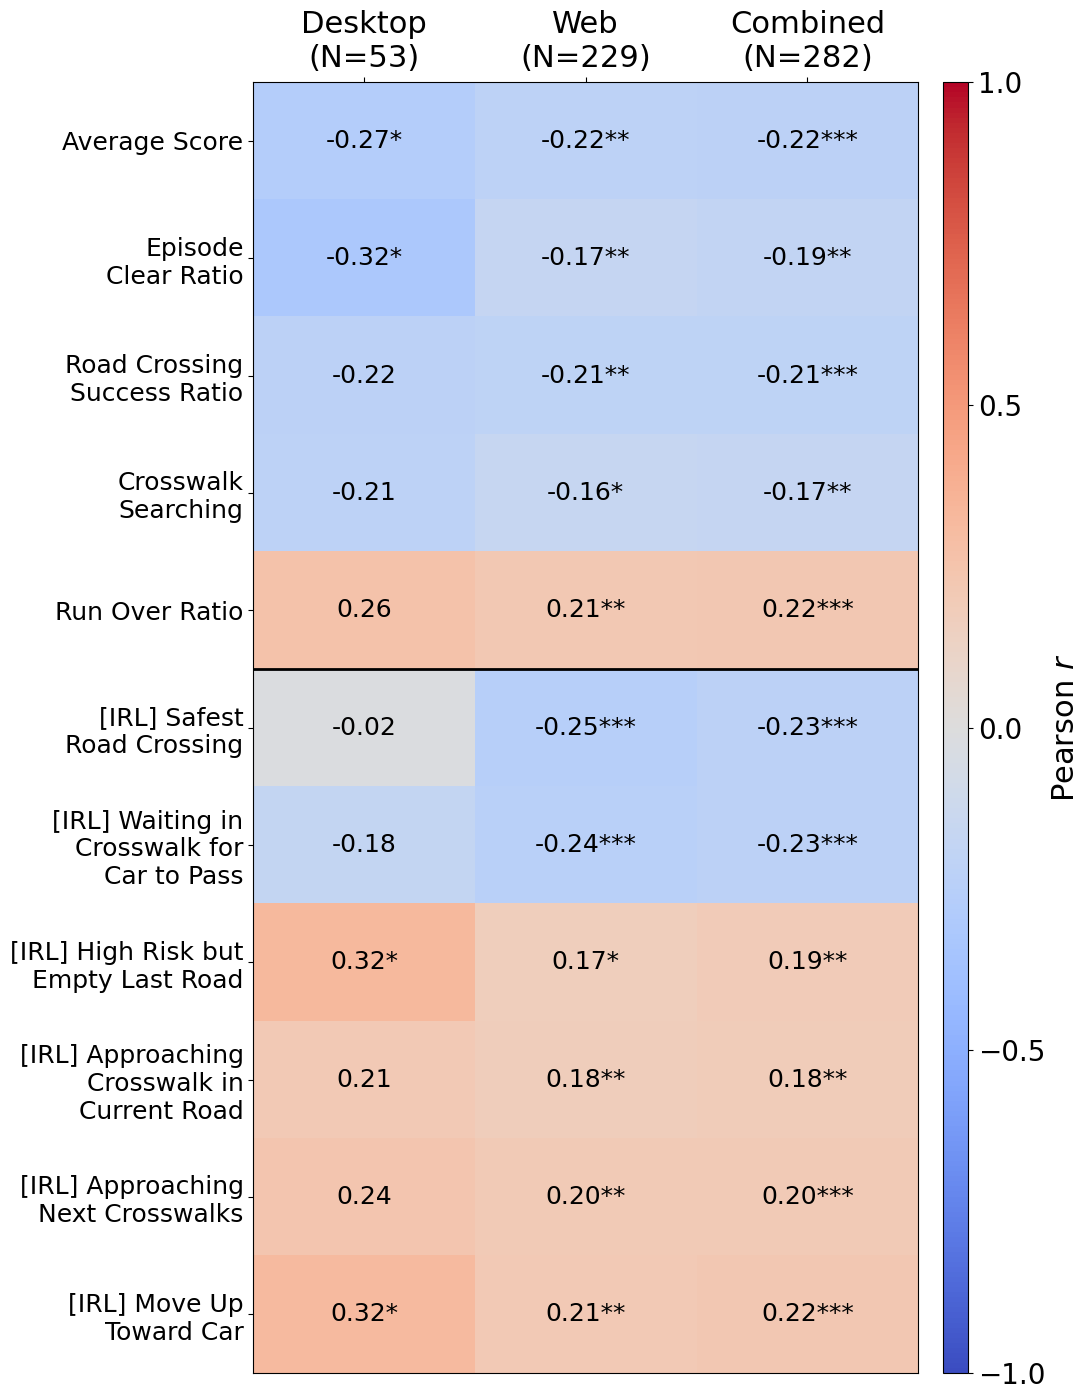

In [ ]:
def plot_dospert_heatmap_transposed(
    score_groups = [
        {
            "score_cols": behavior_cols,
            "score_names": behavior_col_names,
            "idx": [0, 1, 2, 3, 4],
        },
        {
            "score_cols": irl_cols,
            "score_names": irl_col_names,
            "idx": [0, 1, 2, 3, 4, 5],
        },
    ],
    questionnaires=("DOSPERT",),
    study_names=("Desktop", "Web", "Combined"),
    with_r=True,
):
    study_dfs = [
        df[df["web"] == False],
        df[df["web"] == True],
        df,
    ]

    # 열 이름: Desktop, Web, Combined
    study_labels = []
    for study_name, study_df in zip(study_names, study_dfs):
        n = study_df["subj_id"].dropna().shape[0]
        study_labels.append(f"{study_name}\n(N={n})")

    # 두 score group을 하나로 결합
    all_score_cols = []
    all_score_names = []
    group_boundaries = []

    cumulative_count = 0

    for group in score_groups:
        idx = group["idx"]

        selected_cols = [group["score_cols"][i] for i in idx]
        selected_names = [group["score_names"][i] for i in idx]

        all_score_cols.extend(selected_cols)
        all_score_names.extend(selected_names)

        cumulative_count += len(selected_cols)
        group_boundaries.append(cumulative_count)

    n_questionnaires = len(questionnaires)
    n_scores = len(all_score_cols)
    n_studies = len(study_dfs)

    # questionnaire이 하나라면 11 × 3
    heatmap = np.full(
        (n_questionnaires * n_scores, n_studies),
        np.nan,
    )
    pvals = np.full_like(heatmap, np.nan)

    row_names = []

    row_idx = 0

    for questionnaire in questionnaires:
        for score_col, score_name in zip(
            all_score_cols,
            all_score_names,
        ):
            if n_questionnaires == 1:
                row_names.append(score_name)
            else:
                row_names.append(
                    f"{questionnaire}\n{score_name}"
                )

            for study_idx, study_df in enumerate(study_dfs):
                sub = study_df[
                    [questionnaire, score_col]
                ].dropna()

                if len(sub) >= 3:
                    r, p = pearsonr(
                        sub[questionnaire],
                        sub[score_col],
                    )
                else:
                    r, p = np.nan, np.nan

                heatmap[row_idx, study_idx] = r
                pvals[row_idx, study_idx] = p

            row_idx += 1

    fig, ax = plt.subplots(
        figsize=(11, 1.1 * len(row_names) + 2)
    )

    im = ax.imshow(
        heatmap,
        vmin=-1,
        vmax=1,
        cmap="coolwarm",
        aspect="auto",
    )

    # x축: study 3개
    ax.set_xticks(np.arange(n_studies))
    ax.set_xticklabels(
        study_labels,
        fontsize=22,
        rotation=0,
        fontweight=500,
    )
    ax.xaxis.tick_top()
    ax.xaxis.set_label_position("top")

    # y축: score 11개
    ax.set_yticks(np.arange(len(row_names)))
    ax.set_yticklabels(
        row_names,
        fontsize=18,
        fontweight=500,
    )

    # correlation 및 significance 표시
    for i in range(heatmap.shape[0]):
        for j in range(heatmap.shape[1]):
            r = heatmap[i, j]
            p = pvals[i, j]

            if np.isnan(r):
                text = ""
            else:
                star = significance_star(p)
                text = f"{r:.2f}{star}" if with_r else star

            ax.text(
                j,
                i,
                text,
                ha="center",
                va="center",
                fontsize=18,
                color="black",
                fontweight="normal",
            )

    # 첫 번째 테이블과 두 번째 테이블 사이 구분선
    if len(score_groups) > 1:
        boundary = group_boundaries[0]

        for q_idx in range(n_questionnaires):
            offset = q_idx * n_scores

            for boundary in group_boundaries[:-1]:
                ax.axhline(
                    offset + boundary - 0.5,
                    color="black",
                    linewidth=2,
                )

    # questionnaire이 여러 개인 경우 questionnaire 사이 구분선
    for q_idx in range(1, n_questionnaires):
        ax.axhline(
            q_idx * n_scores - 0.5,
            color="black",
            linewidth=3,
        )

    divider = make_axes_locatable(ax)
    cax = divider.append_axes(
        "right",
        size=0.25,
        pad=0.25,
    )

    cbar = fig.colorbar(
        im,
        cax=cax,
        ticks=[-1, -0.5, 0, 0.5, 1],
    )
    cbar.set_label("Pearson $r$", fontsize=22)
    cbar.ax.tick_params(labelsize=20)

    plt.tight_layout()
    plt.show()
plot_dospert_heatmap_transposed()

### DOSPERT subscales

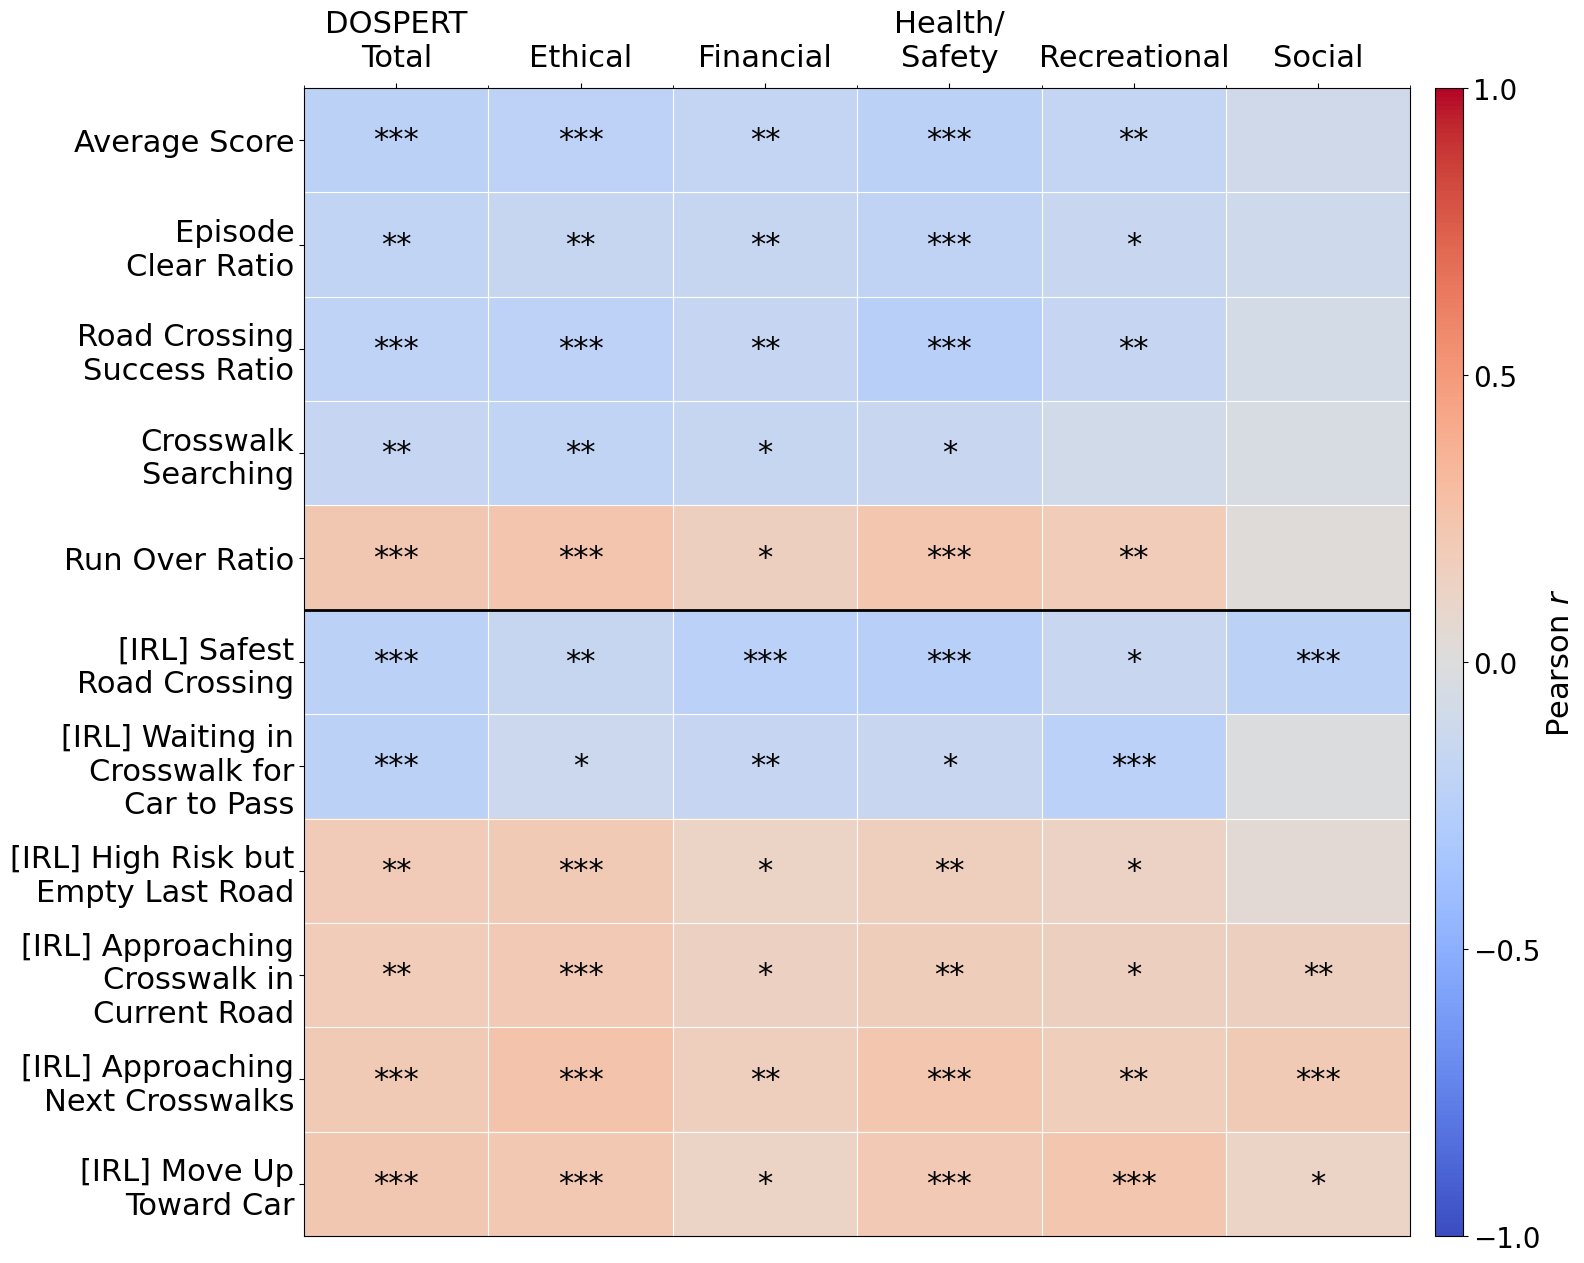

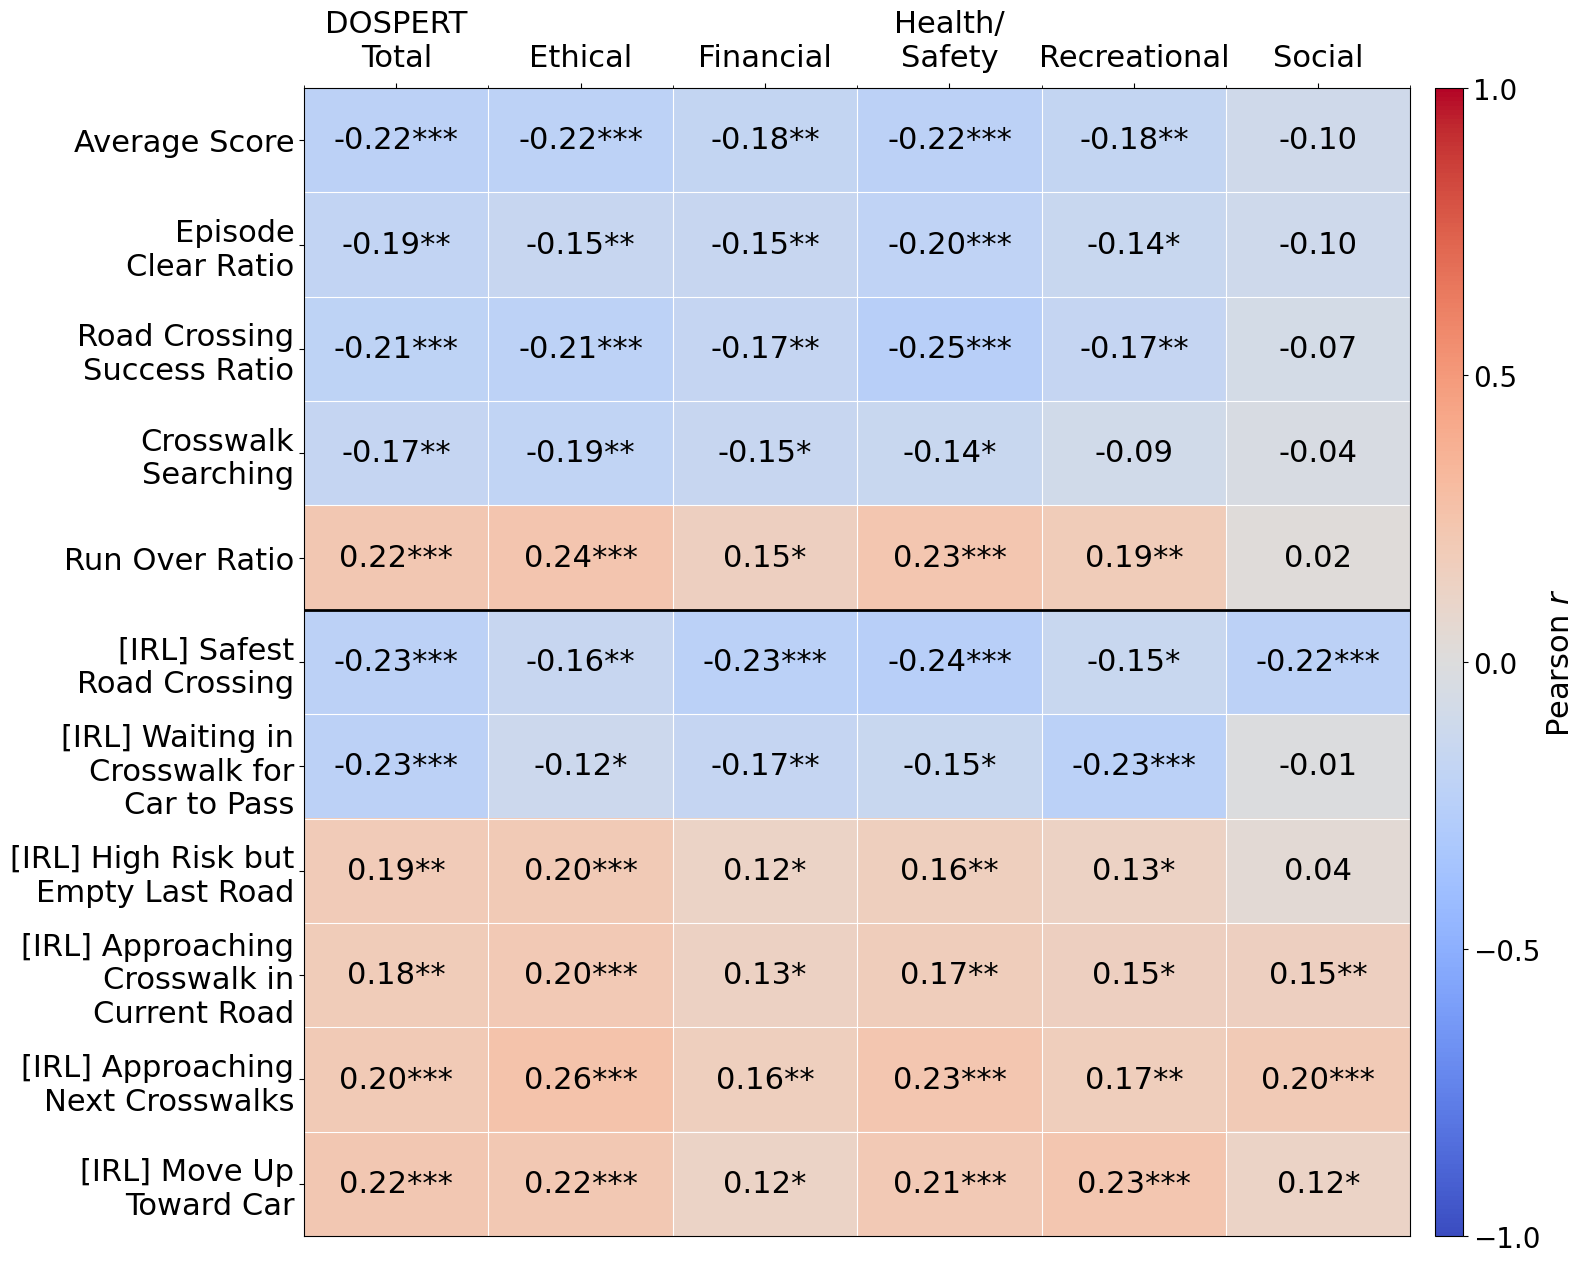

In [113]:
def plot_measure_by_scale_heatmap_DOSPERT(with_r = False):
    plot_measure_by_scale_heatmap(
        data=df,
        measure_cols=all_feature_cols,
        questionnaire_groups = [
            ("DOSPERT", 0, 5),
        ],    
        target_cols=[
            "DOSPERT",
            "DOSPERT_ETH",
            "DOSPERT_FIN",
            "DOSPERT_HEA",
            "DOSPERT_REC",
            "DOSPERT_SOC",
        ],
        target_names = [
            # DOSPERT
            "DOSPERT\nTotal",
            "Ethical",
            "Financial",
            "Health/\nSafety",
            "Recreational",
            "Social",
        ],
        with_r=with_r,
        figsize=(19, 14),
        cell_fontsize=22,
        row_fontsize=22,
        col_fontsize=22,
        group_fontsize=22,
        show_group_names=False,
    )

plot_measure_by_scale_heatmap_DOSPERT(with_r = False)
plot_measure_by_scale_heatmap_DOSPERT(with_r = True)

### BIS/STAI subscales

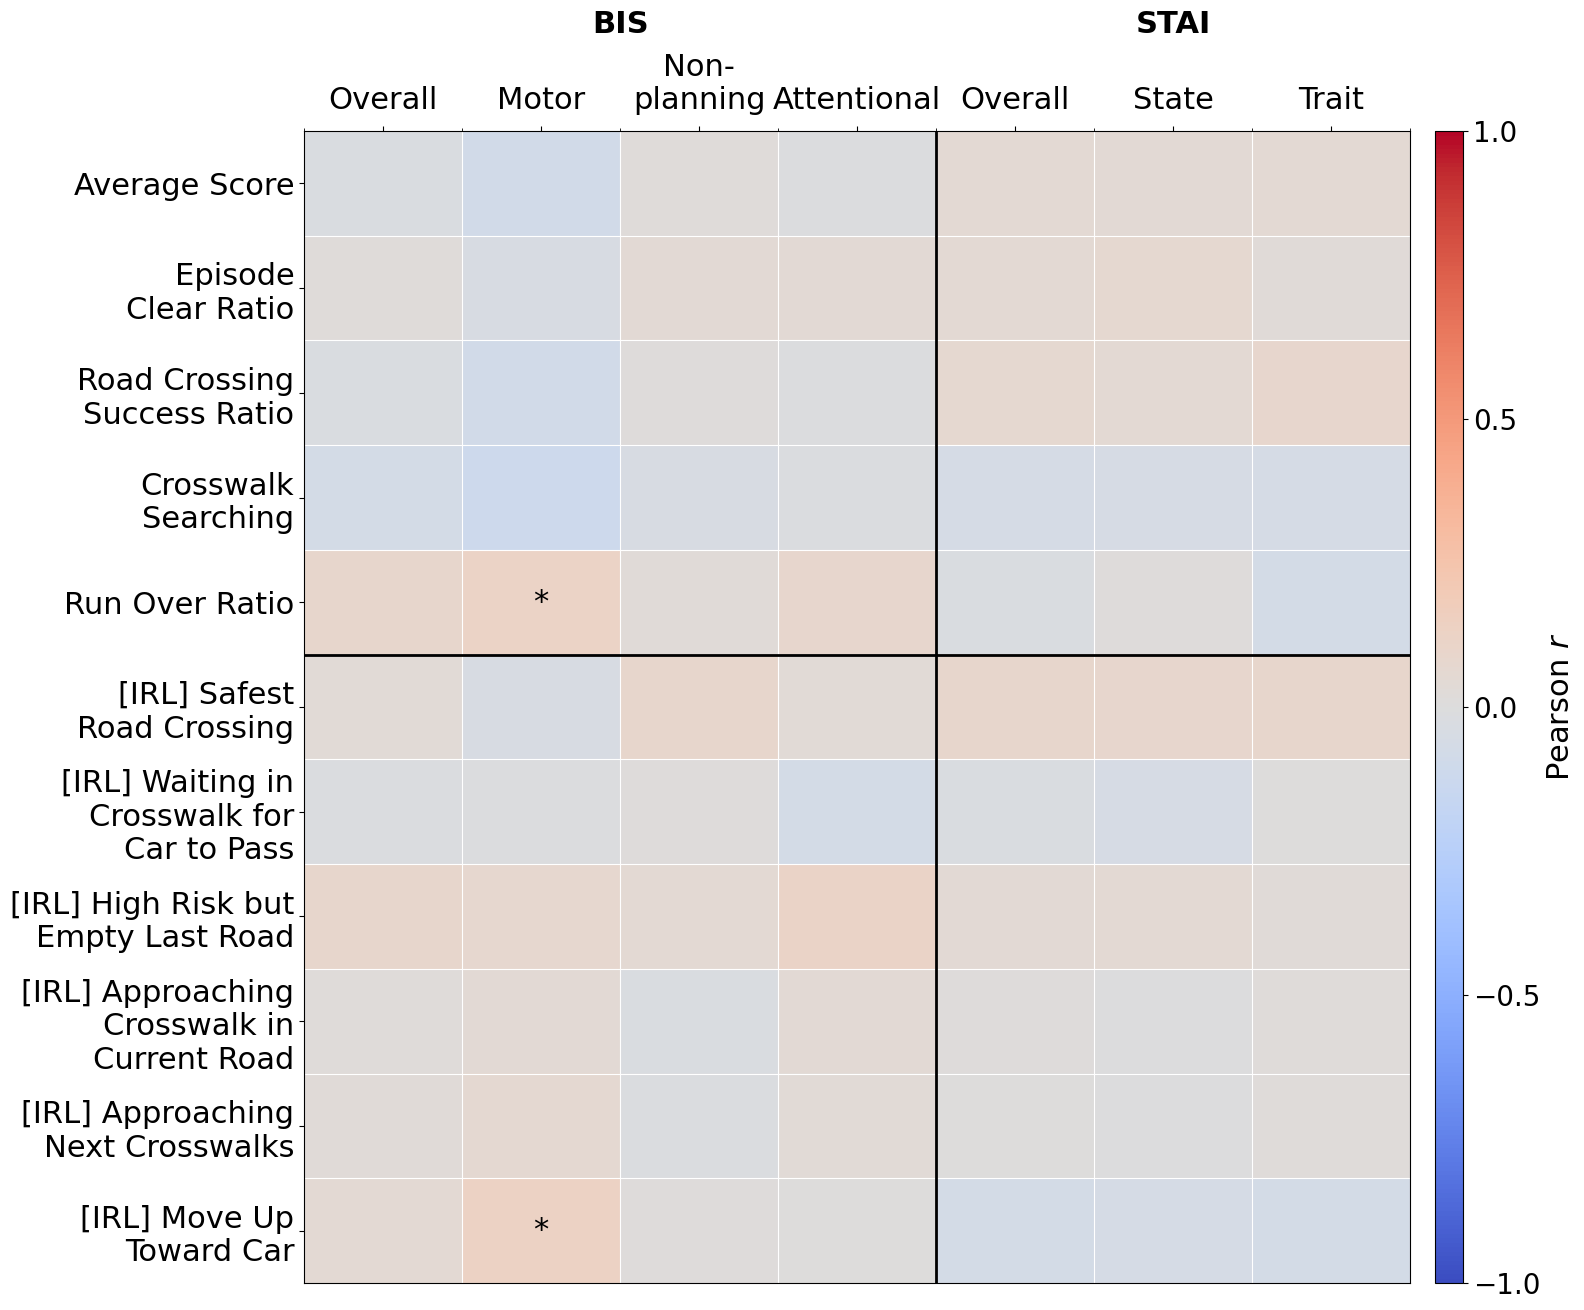

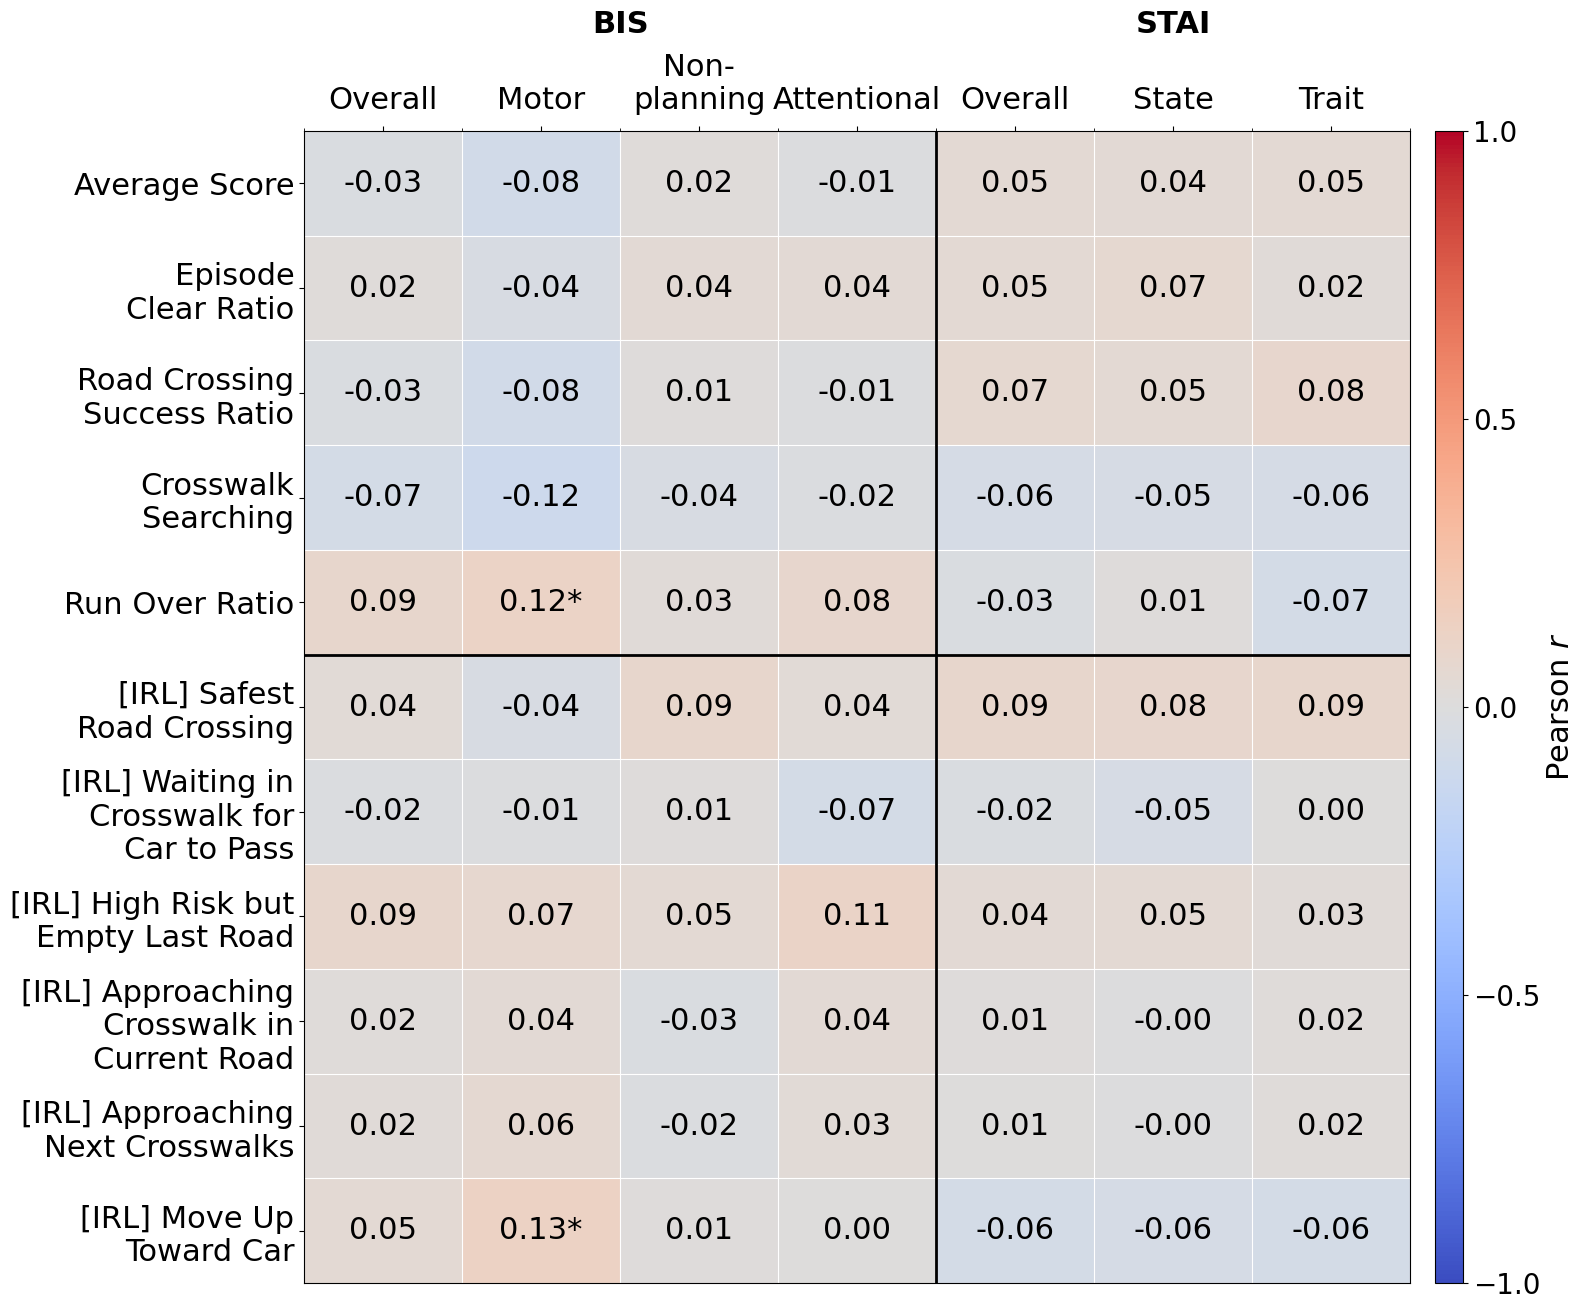

In [114]:
def plot_measure_by_scale_heatmap_BIS_STAI(with_r = False):
    plot_measure_by_scale_heatmap(
        data=df,
        measure_cols=all_feature_cols,
        questionnaire_groups = [
            ("BIS", 0, 3),
            ("STAI", 4, 6),
        ],    
        target_cols=[
            "BIS",
            "BIS_motor",
            "BIS_nonplanning",
            "BIS_attentional",
            
            "STAI",
            "STAI_S",
            "STAI_T",
        ],
        target_names = [
            # BIS
            "Overall",
            "Motor",
            "Non-\nplanning",
            "Attentional",

            # STAI
            "Overall",
            "State",
            "Trait",
        ],
        with_r=with_r,
        figsize=(19, 16),
        cell_fontsize=22,
        row_fontsize=22,
        col_fontsize=22,
        group_fontsize=22,
        show_group_names=True,
    )

plot_measure_by_scale_heatmap_BIS_STAI(with_r = False)
plot_measure_by_scale_heatmap_BIS_STAI(with_r = True)

## Behavior Indicators: Penalty Difference

### Road Crossing success ratio

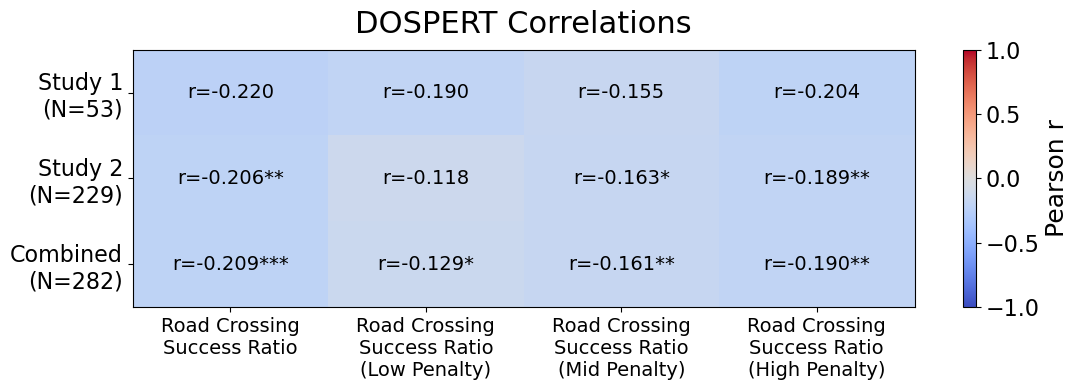

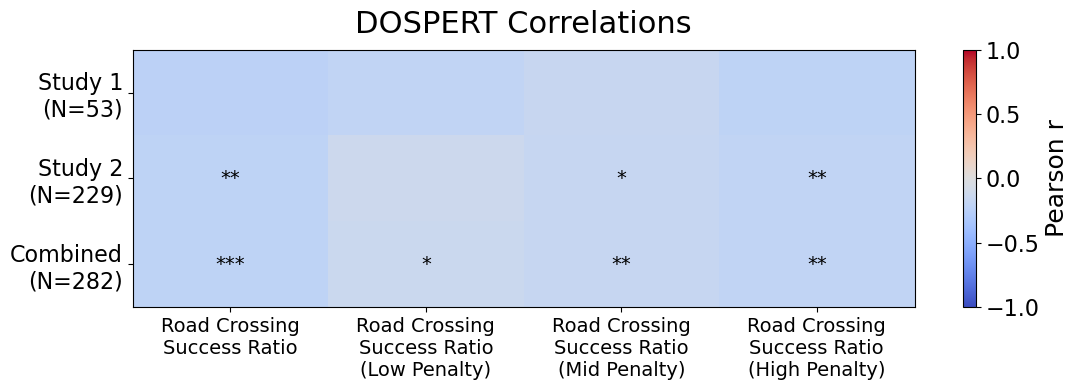

In [ ]:
def significance_star(p):
    if p < 0.001:
        return "***"
    elif p < 0.01:
        return "**"
    elif p < 0.05:
        return "*"
    return ""

def plot(with_r=False):
    questionnaire="DOSPERT"
    score_cols = [
        "road_crossing_success_ratio_total",
        "road_crossing_success_ratio_low_penalty",
        "road_crossing_success_ratio_mid_penalty",
        "road_crossing_success_ratio_high_penalty",
    ]

    score_names = [
        "Road Crossing\nSuccess Ratio", 
        "Road Crossing\nSuccess Ratio\n(Low Penalty)",
        "Road Crossing\nSuccess Ratio\n(Mid Penalty)",
        "Road Crossing\nSuccess Ratio\n(High Penalty)",
    ]

    dfs = [df[df["web"] == False], df[df["web"] == True], df]
    row_names = []
    heatmap = np.zeros((len(dfs), len(score_cols)))
    pvals = np.zeros((len(dfs), len(score_cols)))

    for i in range(3):
        N = len(list(dfs[i]["subj_id"]))
        row_names.append([f"Study 1\n(N={N})", f"Study 2\n(N={N})", f"Combined\n(N={N})"][i])
        for j, col in enumerate(score_cols):
            sub = dfs[i][[questionnaire, col]].dropna()
            if len(sub) >= 3:
                r, p = pearsonr(sub[questionnaire], sub[col])
            else:
                r, p = np.nan, np.nan

            heatmap[i, j] = r
            pvals[i, j] = p

    fig, ax = plt.subplots(figsize=(2.5 + 2.2 * len(score_cols), 4))

    im = ax.imshow(
        heatmap,
        vmin=-1,
        vmax=1,
        cmap="coolwarm",
        aspect="auto"
    )

    ax.set_xticks(np.arange(len(score_names)))
    ax.set_xticklabels(score_names, fontsize=14, rotation=0) #, ha="right")

    ax.set_yticks(np.arange(len(row_names)))
    ax.set_yticklabels(row_names, fontsize=16)

    ax.set_title(f"{questionnaire} Correlations", fontsize=22, pad=12)

    for i in range(len(dfs)):
        for j in range(len(score_cols)):
            r = heatmap[i, j]
            p = pvals[i, j]
            star = significance_star(p)
            text=star
            if with_r:
                text = f"r={r:.3f}{star}"
            ax.text(
                j, i, text,
                ha="center",
                va="center",
                fontsize=14,
                color="black"
            )

    cbar = fig.colorbar(im, ax=ax)
    cbar.set_label("Pearson r", fontsize=18)
    cbar.ax.tick_params(labelsize=16)

    plt.tight_layout()
    plt.show()
plot(with_r=True)
plot(with_r=False)

Combined
Low vs Mid: t=3.199, p=0.0015
Low vs High: t=2.707, p=0.0072
Mid vs High: t=-0.159, p=0.8737


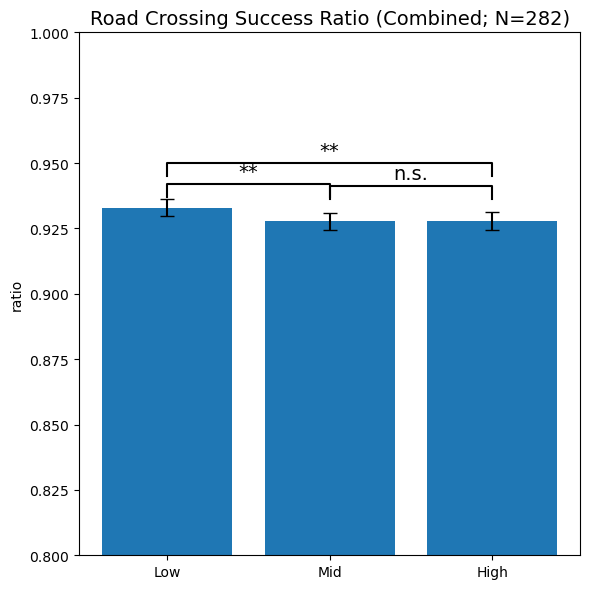

In [116]:
def plot_penalty_ratio_bar_with_stats(web = None):
    labels = ["Low", "Mid", "High"]
    if web is None:
        dataframe = df
        title = f"Road Crossing Success Ratio (Combined; N={len(list(dataframe['subj_id']))})"
    elif web:
        dataframe = df[df["web"] == True]
        title = f"Road Crossing Success Ratio (Web; N={len(list(dataframe['subj_id']))})"
    else:
        dataframe = df[df["web"] == False]
        title = f"Road Crossing Success Ratio (Desktop; N={len(list(dataframe['subj_id']))})"
    data = [
        dataframe["road_crossing_success_ratio_low_penalty"].values,
        dataframe["road_crossing_success_ratio_mid_penalty"].values,
        dataframe["road_crossing_success_ratio_high_penalty"].values,
    ]

    data_clean = []
    for d in data:
        data_clean.append(np.array(d))

    stacked = np.vstack(data_clean).T
    stacked = stacked[~np.isnan(stacked).any(axis=1)]

    low, mid, high = stacked[:,0], stacked[:,1], stacked[:,2]

    means = [np.mean(low), np.mean(mid), np.mean(high)]
    stds  = [np.std(low, ddof=0), np.std(mid, ddof=0), np.std(high, ddof=0)]
    N = len(low)
    ses = [s / np.sqrt(N) for s in stds]
    ci = [1.96 * se for se in ses]

    x = np.arange(3)
    plt.figure(figsize=(6,6))
    plt.bar(x, means, yerr=ci, capsize=5)
    plt.xticks(x, labels)
    plt.ylabel("ratio")
    plt.title(title, fontsize=14)

    pairs = [
        (0, 1, low, mid, 0.001),
        (0, 2, low, high, 0.009),
        (1, 2, mid, high, 0.005),
    ]

    for i, j, a, b, y_offset in pairs:
        stat, p = ttest_rel(a, b)

        if p < 0.001:
            star = "***"
        elif p < 0.01:
            star = "**"
        elif p < 0.05:
            star = "*"
        else:
            star = "n.s."

        base_y = max(means[i] + ci[i], means[j] + ci[j])
        y_max = base_y + y_offset

        bracket_height = 0.005
        text_offset = 0.001

        plt.plot(
            [i, i, j, j],
            [y_max, y_max + bracket_height, y_max + bracket_height, y_max],
            lw=1.5,
            color="black"
        )

        plt.text(
            (i + j) / 2,
            y_max + bracket_height + text_offset,
            star,
            ha='center',
            va='bottom',
            fontsize=14
        )

        print(f"{labels[i]} vs {labels[j]}: t={stat:.3f}, p={p:.4f}")

    plt.ylim(0.8, 1)
    plt.tight_layout()
    plt.show()

for i in range(1): #3):
    web = [None, True, False][i]
    print(["Combined", "Web", "Desktop"][i])
    plot_penalty_ratio_bar_with_stats(web=web)

### Run over ratio

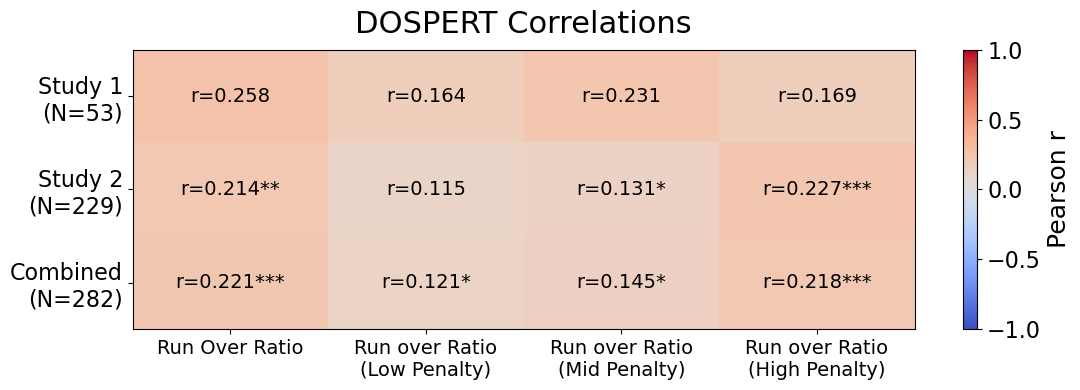

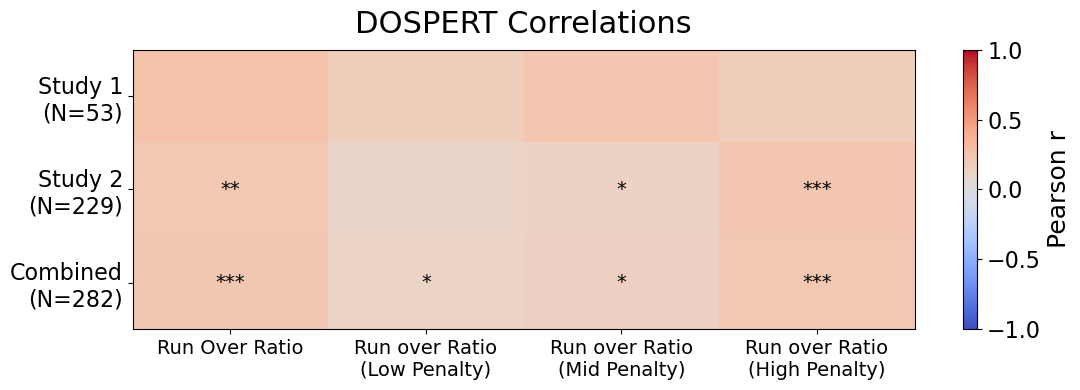

In [ ]:
def significance_star(p):
    if p < 0.001:
        return "***"
    elif p < 0.01:
        return "**"
    elif p < 0.05:
        return "*"
    return ""

def plot(with_r=False):
    questionnaire="DOSPERT"
    score_cols = [
        "run_over_episode_ratio",

        "low_penalty_full_ratio",
        "mid_penalty_full_ratio",
        "high_penalty_full_ratio",
    ]

    score_names = [
        "Run Over Ratio",

        "Run over Ratio\n(Low Penalty)",
        "Run over Ratio\n(Mid Penalty)",
        "Run over Ratio\n(High Penalty)", 
    ]

    dfs = [df[df["web"] == False], df[df["web"] == True], df]
    row_names = []
    heatmap = np.zeros((len(dfs), len(score_cols)))
    pvals = np.zeros((len(dfs), len(score_cols)))

    for i in range(3):
        N = len(list(dfs[i]["subj_id"]))
        row_names.append([f"Study 1\n(N={N})", f"Study 2\n(N={N})", f"Combined\n(N={N})"][i])
        for j, col in enumerate(score_cols):
            sub = dfs[i][[questionnaire, col]].dropna()
            if len(sub) >= 3:
                r, p = pearsonr(sub[questionnaire], sub[col])
            else:
                r, p = np.nan, np.nan

            heatmap[i, j] = r
            pvals[i, j] = p

    fig, ax = plt.subplots(figsize=(2.5 + 2.2 * len(score_cols), 4))

    im = ax.imshow(
        heatmap,
        vmin=-1,
        vmax=1,
        cmap="coolwarm",
        aspect="auto"
    )

    ax.set_xticks(np.arange(len(score_names)))
    ax.set_xticklabels(score_names, fontsize=14, rotation=0) #, ha="right")

    ax.set_yticks(np.arange(len(row_names)))
    ax.set_yticklabels(row_names, fontsize=16)

    ax.set_title(f"{questionnaire} Correlations", fontsize=22, pad=12)

    for i in range(len(dfs)):
        for j in range(len(score_cols)):
            r = heatmap[i, j]
            p = pvals[i, j]
            star = significance_star(p)
            text=star
            if with_r:
                text = f"r={r:.3f}{star}"
            ax.text(
                j, i, text,
                ha="center",
                va="center",
                fontsize=14,
                color="black"
            )

    cbar = fig.colorbar(im, ax=ax)
    cbar.set_label("Pearson r", fontsize=18)
    cbar.ax.tick_params(labelsize=16)

    plt.tight_layout()
    plt.show()
plot(with_r=True)
plot(with_r=False)

Combined
Low vs Mid: t=-6.318, p=0.0000
Low vs High: t=-5.998, p=0.0000
Mid vs High: t=-0.604, p=0.5463


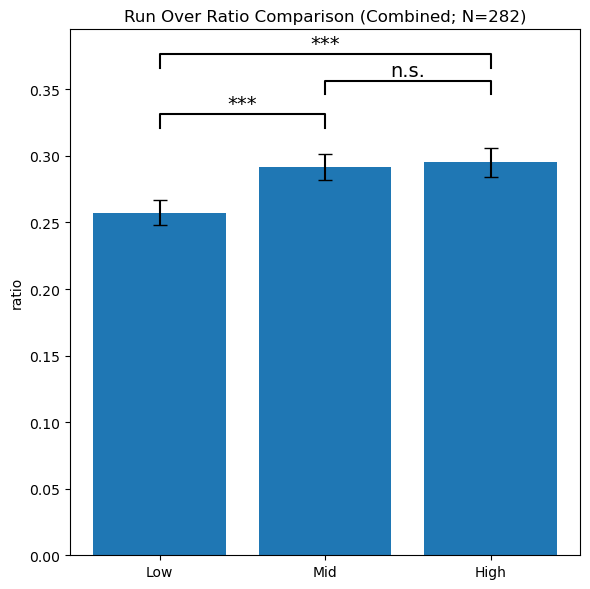

In [118]:
def plot_penalty_ratio_bar_with_stats(web = None):
    labels = ["Low", "Mid", "High"]
    if web is None:
        dataframe = df
        title = f"Run Over Ratio Comparison (Combined; N={len(list(dataframe['subj_id']))})"
    elif web:
        dataframe = df[df["web"] == True]
        title = f"Run Over Ratio Comparison (Web; N={len(list(dataframe['subj_id']))})"
    else:
        dataframe = df[df["web"] == False]
        title = f"Run Over Ratio Comparison (Desktop; N={len(list(dataframe['subj_id']))})"
    data = [
        dataframe["low_penalty_full_ratio"].values,
        dataframe["mid_penalty_full_ratio"].values,
        dataframe["high_penalty_full_ratio"].values,
    ]

    data_clean = []
    for d in data:
        data_clean.append(np.array(d))

    stacked = np.vstack(data_clean).T
    stacked = stacked[~np.isnan(stacked).any(axis=1)]

    low, mid, high = stacked[:,0], stacked[:,1], stacked[:,2]

    means = [np.mean(low), np.mean(mid), np.mean(high)]
    stds  = [np.std(low, ddof=0), np.std(mid, ddof=0), np.std(high, ddof=0)]
    N = len(low)
    ses = [s / np.sqrt(N) for s in stds]
    ci = [1.96 * se for se in ses]

    x = np.arange(3)
    plt.figure(figsize=(6,6))
    plt.bar(x, means, yerr=ci, capsize=5)
    plt.xticks(x, labels)
    plt.ylabel("ratio")
    plt.title(title)

    pairs = [
        (0, 1, low, mid, 0.02),
        (0, 2, low, high, 0.06),
        (1, 2, mid, high, 0.04),
    ]

    for i, j, a, b, y_offset in pairs:
        stat, p = ttest_rel(a, b)

        if p < 0.001:
            star = "***"
        elif p < 0.01:
            star = "**"
        elif p < 0.05:
            star = "*"
        else:
            star = "n.s."

        base_y = max(means[i] + ci[i], means[j] + ci[j])
        y_max = base_y + y_offset

        bracket_height = 0.01
        text_offset = 0.001

        plt.plot(
            [i, i, j, j],
            [y_max, y_max + bracket_height, y_max + bracket_height, y_max],
            lw=1.5,
            color="black"
        )

        plt.text(
            (i + j) / 2,
            y_max + bracket_height + text_offset,
            star,
            ha='center',
            va='bottom',
            fontsize=14
        )

        print(f"{labels[i]} vs {labels[j]}: t={stat:.3f}, p={p:.4f}")

    plt.tight_layout()
    plt.show()

for i in range(1): #3):
    web = [None, True, False][i]
    print(["Combined", "Web", "Desktop"][i])
    plot_penalty_ratio_bar_with_stats(web=web)